# Mechanics 2: Energy and momentum

*Learning path: mechanics, part 2 of 7.* [Index](README.md) · Previous: [Motion and Newton's laws](01-motion-and-newtons-laws.ipynb) · Next: [Rotation](03-rotation.ipynb)

To reach low Earth orbit a rocket must go about 7.8 km/s. Its engines push hot gas out at about 3 km/s. How can
something go faster than what it pushes against? And why does every orbital rocket throw away most of itself in stages
on the way up? The answers come from **momentum**, one of two quantities that never change in an isolated system. The
other is **energy**. This lesson shows how both follow from Newton's laws, and how they answer questions (collisions,
speeds after a fall, rockets) without solving any equation of motion in detail.

**Who this is for.** You have done [lesson 1](01-motion-and-newtons-laws.ipynb).

**What you will be able to do afterwards:**

1. compute work as an integral of force, and use the work–energy theorem;
2. use conservation of energy with gravitational and spring potential energy;
3. solve elastic and inelastic collisions with conservation of momentum (and energy);
4. derive the rocket equation $\Delta v = u\log(m_0/m_1)$ and see why rockets have stages.

Plan about an hour and a half.

## 1. Work and kinetic energy

A force $F$ pushing an object along $x$ does **work** $W = \int F\,dx$. By Newton's second law, $F = m\,dv/dt$, and
$dx = v\,dt$, so $W = \int m v\,dv = \tfrac12 mv_1^2 - \tfrac12 mv_0^2$: the work done equals the change in the
**kinetic energy** $K = \tfrac12 mv^2$. Stretching a spring with force $F = kx$ to extension $A$ takes

In [1]:
integrate(k*x, x, 0, A)

A^2*k/2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

A car braking with friction coefficient $\mu$ is slowed by the force $\mu mg$. All its kinetic energy goes into that
work over the braking distance $d$: $\mu m g d = \tfrac12 mv^2$, so $d = v^2/(2\mu g)$, whatever the mass. On dry
asphalt $\mu \approx 0.7$:

In [2]:
d(v) := v^2/(2*0.7*const.g);
eval(d(50 km/h), 3)
eval(d(100 km/h), 3)

14.1 m

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

56.2 m

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Twice the speed, four times the distance. That is why speed limits near schools are so low.

**Try this.** On wet asphalt $\mu \approx 0.4$. What is the braking distance from 100 km/h?

## 2. Potential energy and conservation

Some forces give back the work done against them. Lifting a mass $m$ by a height $h$ against gravity takes work $mgh$,
and the mass gets it back when it falls. Such forces have a **potential energy** $U$, with $F = -dU/dx$: $U = mgy$ for
gravity near the ground and $U = \tfrac12 kx^2$ for a spring. Then the **total energy** $E = K + U$ stays constant.
Check it on the projectile of lesson 1:

In [3]:
r = [vx*t, vy*t - g*t^2/2];
vel = diff(r, t);
E = m*(vel(1)^2 + vel(2)^2)/2 + m*g*r(2);
simplify(E)

m*(vx^2+vy^2)/2

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

The time has dropped out. Energy conservation gives speeds without solving the motion: a roller coaster that starts
from rest 20 m above the bottom of a dip reaches it with $\tfrac12mv^2 = mgh$, $v = \sqrt{2gh}$, whatever the shape of
the track (if friction is small):

In [4]:
eval(sqrt(2*const.g*(20 m)), 3)
eval(convert(sqrt(2*const.g*(20 m)), km/h), 3)

19.8 m/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

71.3 km/h

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Here are kinetic and potential energy along the flight of a 1 kg ball thrown up at 15 m/s; their sum stays at
112.5 J:

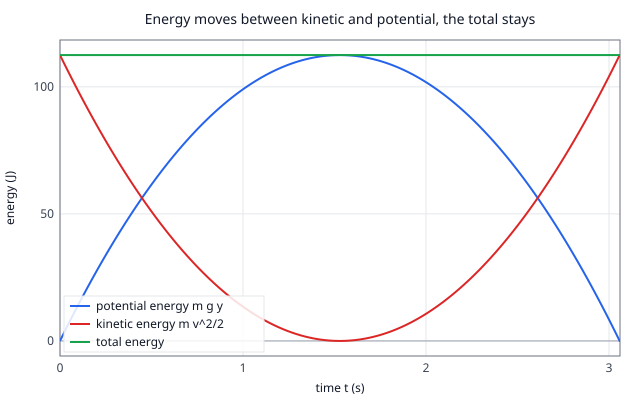

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
y(t) := 15*t - 9.81*t^2/2;
p = plot(9.81*y(t), t, 0, 3.06);
p = show(p, plot((15 - 9.81*t)^2/2, t, 0, 3.06));
p = show(p, plot(9.81*y(t) + (15 - 9.81*t)^2/2, t, 0, 3.06));
p = legend(p, "potential energy m g y", "kinetic energy m v^2/2", "total energy");
labels(title(p, "Energy moves between kinetic and potential, the total stays"), "time t (s)", "energy (J)")

**Try this.** A spring with $k = 400$ N/m is compressed by 10 cm and launches a 50 g ball straight up. How high does
the ball go? (Set $\tfrac12kx^2 = mgh$.)

## 3. Momentum and collisions

The **momentum** of a body is $\mathbf p = m\mathbf v$. When two bodies push on each other, Newton's third law makes
the forces equal and opposite, so the momentum one gains the other loses: **the total momentum of an isolated system
is conserved**. In a collision the forces are huge and brief, but the total momentum before equals the total after.

In an **elastic** collision (billiard balls, approximately) kinetic energy is conserved too. For a ball of mass $m_1$
at speed $u_1$ hitting a ball $m_2$ at rest, both laws together fix the speeds afterwards:

In [6]:
solve([m1*u1 == m1*v1 + m2*v2, m1*u1^2 == m1*v1^2 + m2*v2^2], [v1 v2])

[                u1,               0;
 u1*(m1-m2)/(m1+m2), 2*m1*u1/(m1+m2)]

> Real solutions of the system, one per row (v1, v2). Found by eliminating unknowns one at a time (substitution, factoring and resultants); complex solutions are left out. A row that still contains an unknown is a whole family of solutions: that unknown can take any value (for example [y, y] means every point with x = y).

The first row is the trivial solution (no collision). The second is the answer: $v_1 = u_1(m_1 - m_2)/(m_1 + m_2)$,
$v_2 = 2m_1u_1/(m_1 + m_2)$. Equal masses swap speeds, which is how Newton's cradle works. A light ball bounces off a
heavy one, and a heavy ball barely slows when it hits a light one:

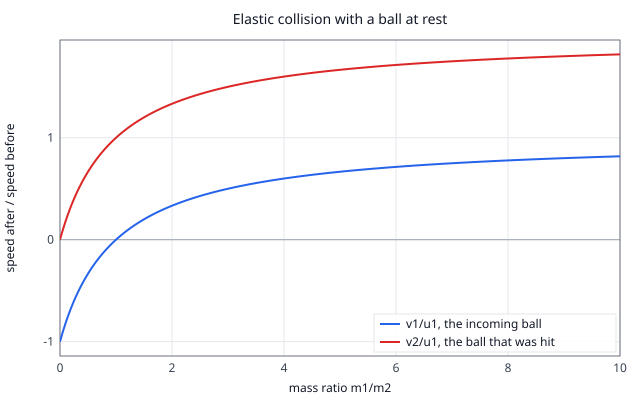

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = plot((x - 1)/(x + 1), x, 0, 10);
p = show(p, plot(2*x/(x + 1), x, 0, 10));
p = legend(p, "v1/u1, the incoming ball", "v2/u1, the ball that was hit");
labels(title(p, "Elastic collision with a ball at rest"), "mass ratio m1/m2", "speed after / speed before")

In an **inelastic** collision the bodies stick together. Momentum is still conserved, $m_1u_1 = (m_1 + m_2)v$, but
kinetic energy is not: some goes into heat and deformation. The fraction kept is $m_1/(m_1 + m_2)$:

In [8]:
v = m1*u1/(m1 + m2);
simplify(((m1 + m2)*v^2/2)/(m1*u1^2/2))

m1/(m1+m2)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

**Try this.** A 10 g bullet hits and sticks in a 2 kg wooden block hanging from strings, which then swings up 8 cm
(a **ballistic pendulum**). How fast was the bullet? (Momentum through the collision, then energy for the swing.)

## 4. Rockets

A rocket in empty space has nothing to push against. It throws gas backwards at speed $u$ relative to itself, and
momentum conservation does the rest. In a time $dt$ the rocket of mass $M$ ejects mass $-dM$ at speed $u$ backwards
and gains speed $dv$: $M\,dv = -u\,dM$. As a differential equation for $v$ as a function of the mass:

In [9]:
dsolve(v' == -u/M, v, M, M0, 0)

u*log(M0)-u*log(M)

> `dsolve`: Exact solution of a differential equation written with y, y', y'', ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

This is **Tsiolkovsky's rocket equation** (1903): $\Delta v = u\log(M_0/M_1)$. The speed grows only with the logarithm
of the mass ratio. With $u = 3$ km/s, reaching 7.8 km/s needs a mass ratio of $e^{7.8/3} \approx 13$, and real launches
need about 9.5 km/s because of gravity and air drag:

13.5

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

23.7

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

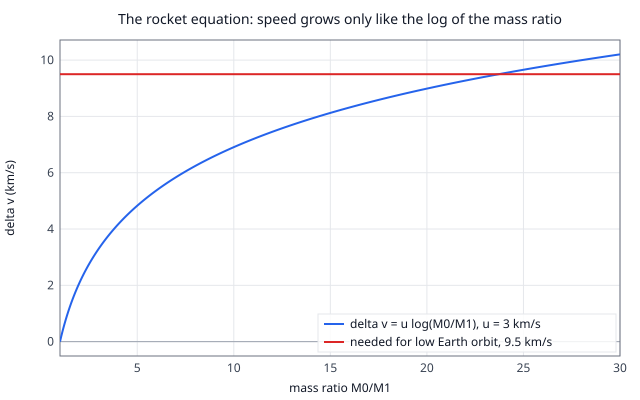

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
u = 3 km/s;
eval(exp(7.8/3), 3)
eval(exp(9.5/3), 3)
p = plot(3*log(x), x, 1, 30);
p = show(p, plot(9.5, x, 1, 30));
p = legend(p, "delta v = u log(M0/M1), u = 3 km/s", "needed for low Earth orbit, 9.5 km/s");
labels(title(p, "The rocket equation: speed grows only like the log of the mass ratio"), "mass ratio M0/M1", "delta v (km/s)")

A mass ratio of 24 means 96% of the rocket at launch is fuel, leaving 4% for tanks, engines and payload. No single
structure is that light. **Staging** solves it: when the first stage's fuel is spent, its empty tanks and engines are
dropped, and the second stage starts with a much smaller mass to push. Two stages, each with a mass ratio of 5:

In [11]:
eval(2*u*log(5), 3)

9.66 km/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

9.66 km/s, enough for orbit, with each stage only 80% fuel. That is why every orbital rocket has at least two stages.

**Try this.** A rocket must give a payload $\Delta v = 9.5$ km/s with $u = 4.4$ km/s (hydrogen and oxygen). What mass
ratio does one stage need?

## Summary

* Work $W = \int F\,dx$ changes the kinetic energy $\tfrac12mv^2$ (the work–energy theorem).
* For conservative forces, $F = -dU/dx$, the energy $K + U$ is conserved; speeds follow without solving the motion.
* Total momentum is conserved in every collision; kinetic energy only in elastic ones. Equal masses swap speeds.
* A rocket reaches $\Delta v = u\log(M_0/M_1)$: logarithmic in the mass ratio, which is why rockets drop empty stages.

Next: [rotation](03-rotation.ipynb), where momentum gets an angular partner.

## Exercises

1. **Stopping power.** A 1500 kg car at 90 km/h stops in 50 m. What is the average braking force?
2. **Pendulum speed.** A pendulum of length 2 m is released from 30 degrees. What is its speed at the bottom?
3. **Newton's cradle.** Show that in an elastic collision of equal masses the balls exchange velocities, using the
   formulas of section 3 with $m_1 = m_2$.
4. **Car crash.** A 1000 kg car at 20 m/s hits a parked 1500 kg car and they move off together. How fast, and what
   fraction of the kinetic energy is lost?
5. **Escape speed.** Using $U = -GMm/r$, find the speed needed to escape the Earth from its surface.
6. **Three stages.** With $u = 3$ km/s and three stages of mass ratio 3, what $\Delta v$ do you get?

## Hints and answers

* **Section 1, Try this.** $d = (27.8)^2/(2 \cdot 0.4 \cdot 9.81) \approx 98$ m, against 56 m when dry.
* **Section 2, Try this.** $h = kx^2/(2mg) = 400 \cdot 0.01/(2 \cdot 0.05 \cdot 9.81) \approx 4.1$ m.
* **Section 3, Try this.** Swing: $v = \sqrt{2gh} = 1.25$ m/s for block and bullet; momentum: $u = v(m + M)/m \approx
  252$ m/s.
* **Section 4, Try this.** $e^{9.5/4.4} \approx 8.7$.
* **Exercise 1.** $F = \tfrac12mv^2/d = 1500 \cdot 25^2/(2 \cdot 50) = 9375$ N.
* **Exercise 2.** The drop is $\ell(1 - \cos 30°) = 0.268$ m, so $v = \sqrt{2gh} \approx 2.29$ m/s.
* **Exercise 3.** $v_1 = 0$ and $v_2 = u_1$.
* **Exercise 4.** $v = 8$ m/s; the kept fraction is $1000/2500 = 40\%$, so 60% is lost.
* **Exercise 5.** $\tfrac12 mv^2 = GMm/R$ gives $v = \sqrt{2GM/R}$: `eval(convert(sqrt(2*const.G*const.Mearth/const.Rearth), km/s), 3)`
  is 11.2 km/s.
* **Exercise 6.** $3u\log 3 \approx 9.89$ km/s.

## Sources

1. K. E. Tsiolkovsky, "Exploration of the world spaces by reactive devices", *Nauchnoe Obozrenie* 5 (1903).
2. C. Huygens, "De motu corporum ex percussione" (1656, published 1703): elastic collisions and the conservation of
   $mv^2$.
3. D. Kleppner and R. Kolenkow, *An Introduction to Mechanics*, 2nd ed., Cambridge University Press (2014), chapters 4
   and 5.
4. G. P. Sutton and O. Biblarz, *Rocket Propulsion Elements*, 9th ed., Wiley (2016), chapter 4 (staging).